In [1]:
#import different libraries:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
#to find block dataset files:
from glob import glob
import os
daily_data = sorted(glob('daily_dataset/block_*.csv') or glob('halfhourly_dataset/halfhourly_dataset/block_*.csv') or glob('**/block_*.csv', recursive=True))
daily_data = [f for f in daily_data if os.path.isfile(f)]
daily_data[:5]


['halfhourly_dataset/halfhourly_dataset\\block_0.csv',
 'halfhourly_dataset/halfhourly_dataset\\block_1.csv',
 'halfhourly_dataset/halfhourly_dataset\\block_10.csv',
 'halfhourly_dataset/halfhourly_dataset\\block_100.csv',
 'halfhourly_dataset/halfhourly_dataset\\block_101.csv']

In [3]:
# Read block files (sample up to 2 blocks for efficient processing if massive dataset):
sample_files = daily_data[:2] if len(daily_data) > 2 else daily_data
def load_block(file):
    df = pd.read_csv(file)
    if 'energy(kWh/hh)' in df.columns:
        df['day'] = df['tstp'].str.slice(0, 10)
        df['energy(kWh/hh)'] = pd.to_numeric(df['energy(kWh/hh)'], errors='coerce')
        agg = df.groupby(['LCLid', 'day'])['energy(kWh/hh)'].agg(
            energy_median='median',
            energy_mean='mean',
            energy_max='max',
            energy_count='count',
            energy_std='std',
            energy_sum='sum',
            energy_min='min'
        ).reset_index()
        return agg.assign(sourcefilename=file)
    return df.assign(sourcefilename=file)

daily_data_merge = pd.concat(load_block(datafile) for datafile in sample_files)
daily_data_merge


,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min,sourcefilename
0,MAC000002,2012-10-12,0.1385,0.154304,0.886,46,0.196034,7.098,0.000,halfhourly_dataset/halfhourly_dataset\block_0.csv
1,MAC000002,2012-10-13,0.1800,0.230979,0.933,48,0.192329,11.087,0.076,halfhourly_dataset/halfhourly_dataset\block_0.csv
2,MAC000002,2012-10-14,0.1580,0.275479,1.085,48,0.274647,13.223,0.070,halfhourly_dataset/halfhourly_dataset\block_0.csv
3,MAC000002,2012-10-15,0.1310,0.213688,1.164,48,0.224483,10.257,0.070,halfhourly_dataset/halfhourly_dataset\block_0.csv
4,MAC000002,2012-10-16,0.1450,0.203521,0.991,48,0.184115,9.769,0.087,halfhourly_dataset/halfhourly_dataset\block_0.csv
...,...,...,...,...,...,...,...,...,...,...
31726,MAC004529,2014-02-24,0.1400,0.193896,1.057,48,0.200382,9.307,0.026,halfhourly_dataset/halfhourly_dataset\block_1.csv
31727,MAC004529,2014-02-25,0.1240,0.180354,1.156,48,0.175504,8.657,0.030,halfhourly_dataset/halfhourly_dataset\block_1.csv
31728,MAC004529,2014-02-26,0.0645,0.151521,0.880,48,0.178791,7.273,0.027,halfhourly_dataset/halfhourly_dataset\block_1.csv
31729,MAC004529,2014-02-27,0.0795,0.151625,0.859,48,0.158759,7.278,0.025,halfhourly_dataset/halfhourly_dataset\block_1.csv


In [4]:
daywise = daily_data_merge.drop(['sourcefilename'], axis = 1)
daywise.head()

,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000002,2012-10-12,0.1385,0.154304,0.886,46,0.196034,7.098,0.000
1,MAC000002,2012-10-13,0.1800,0.230979,0.933,48,0.192329,11.087,0.076
2,MAC000002,2012-10-14,0.1580,0.275479,1.085,48,0.274647,13.223,0.070
3,MAC000002,2012-10-15,0.1310,0.213688,1.164,48,0.224483,10.257,0.070
4,MAC000002,2012-10-16,0.1450,0.203521,0.991,48,0.184115,9.769,0.087


In [5]:
#to fill the empty cell in dataset by using fill forward method and finally prepare this dataset with non-null values: 
daywise_data = daywise.ffill()
daywise_data


,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000002,2012-10-12,0.1385,0.154304,0.886,46,0.196034,7.098,0.000
1,MAC000002,2012-10-13,0.1800,0.230979,0.933,48,0.192329,11.087,0.076
2,MAC000002,2012-10-14,0.1580,0.275479,1.085,48,0.274647,13.223,0.070
3,MAC000002,2012-10-15,0.1310,0.213688,1.164,48,0.224483,10.257,0.070
4,MAC000002,2012-10-16,0.1450,0.203521,0.991,48,0.184115,9.769,0.087
...,...,...,...,...,...,...,...,...,...
31726,MAC004529,2014-02-24,0.1400,0.193896,1.057,48,0.200382,9.307,0.026
31727,MAC004529,2014-02-25,0.1240,0.180354,1.156,48,0.175504,8.657,0.030
31728,MAC004529,2014-02-26,0.0645,0.151521,0.880,48,0.178791,7.273,0.027
31729,MAC004529,2014-02-27,0.0795,0.151625,0.859,48,0.158759,7.278,0.025


In [6]:
#to load weather daily darksky dataset and to extract date and time:
weather_daily_data = pd.read_csv('weather_daily_darksky.csv')
weather_daily_data = pd.DataFrame({'temperatureMaxTime':pd.date_range('2011-11-11 23:00:00',periods=len(weather_daily_data))})
weather_daily_data['day'] = pd.to_datetime(weather_daily_data['temperatureMaxTime']).dt.date
weather_daily_data['time'] = pd.to_datetime(weather_daily_data['temperatureMaxTime']).dt.time
weather_daily_data


,temperatureMaxTime,day,time
0,2011-11-11 23:00:00,2011-11-11,23:00:00
1,2011-11-12 23:00:00,2011-11-12,23:00:00
2,2011-11-13 23:00:00,2011-11-13,23:00:00
3,2011-11-14 23:00:00,2011-11-14,23:00:00
4,2011-11-15 23:00:00,2011-11-15,23:00:00
...,...,...,...
877,2014-04-06 23:00:00,2014-04-06,23:00:00
878,2014-04-07 23:00:00,2014-04-07,23:00:00
879,2014-04-08 23:00:00,2014-04-08,23:00:00
880,2014-04-09 23:00:00,2014-04-09,23:00:00


In [7]:
weather_original = pd.read_csv('weather_daily_darksky.csv')
weather_original.head(4)


,temperatureMax,temperatureMaxTime,windBearing,icon,dewPoint,temperatureMinTime,cloudCover,windSpeed,pressure,apparentTemperatureMinTime,...,temperatureHigh,sunriseTime,temperatureHighTime,uvIndexTime,summary,temperatureLowTime,apparentTemperatureMin,apparentTemperatureMaxTime,apparentTemperatureLowTime,moonPhase
0,11.96,2011-11-11 23:00:00,123,fog,9.40,2011-11-11 07:00:00,0.79,3.88,1016.08,2011-11-11 07:00:00,...,10.87,2011-11-11 07:12:14,2011-11-11 19:00:00,2011-11-11 11:00:00,Foggy until afternoon.,2011-11-11 19:00:00,6.48,2011-11-11 23:00:00,2011-11-11 19:00:00,0.52
1,8.59,2011-12-11 14:00:00,198,partly-cloudy-day,4.49,2011-12-11 01:00:00,0.56,3.94,1007.71,2011-12-11 02:00:00,...,8.59,2011-12-11 07:57:02,2011-12-11 14:00:00,2011-12-11 12:00:00,Partly cloudy throughout the day.,2011-12-12 07:00:00,0.11,2011-12-11 20:00:00,2011-12-12 08:00:00,0.53
2,10.33,2011-12-27 02:00:00,225,partly-cloudy-day,5.47,2011-12-27 23:00:00,0.85,3.54,1032.76,2011-12-27 22:00:00,...,10.33,2011-12-27 08:07:06,2011-12-27 14:00:00,2011-12-27 00:00:00,Mostly cloudy throughout the day.,2011-12-27 23:00:00,5.59,2011-12-27 02:00:00,2011-12-28 00:00:00,0.10
3,8.07,2011-12-02 23:00:00,232,wind,3.69,2011-12-02 07:00:00,0.32,3.00,1012.12,2011-12-02 07:00:00,...,7.36,2011-12-02 07:46:09,2011-12-02 12:00:00,2011-12-02 10:00:00,Partly cloudy throughout the day and breezy ov...,2011-12-02 19:00:00,0.46,2011-12-02 12:00:00,2011-12-02 19:00:00,0.25


In [8]:
weather_updated = pd.concat([weather_daily_data, weather_original], axis = 'columns')
weather_updated

,temperatureMaxTime,day,time,temperatureMax,temperatureMaxTime,windBearing,icon,dewPoint,temperatureMinTime,cloudCover,...,temperatureHigh,sunriseTime,temperatureHighTime,uvIndexTime,summary,temperatureLowTime,apparentTemperatureMin,apparentTemperatureMaxTime,apparentTemperatureLowTime,moonPhase
0,2011-11-11 23:00:00,2011-11-11,23:00:00,11.96,2011-11-11 23:00:00,123,fog,9.40,2011-11-11 07:00:00,0.79,...,10.87,2011-11-11 07:12:14,2011-11-11 19:00:00,2011-11-11 11:00:00,Foggy until afternoon.,2011-11-11 19:00:00,6.48,2011-11-11 23:00:00,2011-11-11 19:00:00,0.52
1,2011-11-12 23:00:00,2011-11-12,23:00:00,8.59,2011-12-11 14:00:00,198,partly-cloudy-day,4.49,2011-12-11 01:00:00,0.56,...,8.59,2011-12-11 07:57:02,2011-12-11 14:00:00,2011-12-11 12:00:00,Partly cloudy throughout the day.,2011-12-12 07:00:00,0.11,2011-12-11 20:00:00,2011-12-12 08:00:00,0.53
2,2011-11-13 23:00:00,2011-11-13,23:00:00,10.33,2011-12-27 02:00:00,225,partly-cloudy-day,5.47,2011-12-27 23:00:00,0.85,...,10.33,2011-12-27 08:07:06,2011-12-27 14:00:00,2011-12-27 00:00:00,Mostly cloudy throughout the day.,2011-12-27 23:00:00,5.59,2011-12-27 02:00:00,2011-12-28 00:00:00,0.10
3,2011-11-14 23:00:00,2011-11-14,23:00:00,8.07,2011-12-02 23:00:00,232,wind,3.69,2011-12-02 07:00:00,0.32,...,7.36,2011-12-02 07:46:09,2011-12-02 12:00:00,2011-12-02 10:00:00,Partly cloudy throughout the day and breezy ov...,2011-12-02 19:00:00,0.46,2011-12-02 12:00:00,2011-12-02 19:00:00,0.25
4,2011-11-15 23:00:00,2011-11-15,23:00:00,8.22,2011-12-24 23:00:00,252,partly-cloudy-night,2.79,2011-12-24 07:00:00,0.37,...,7.93,2011-12-24 08:06:15,2011-12-24 15:00:00,2011-12-24 13:00:00,Mostly cloudy throughout the day.,2011-12-24 19:00:00,-0.51,2011-12-24 23:00:00,2011-12-24 20:00:00,0.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06 23:00:00,2014-04-06,23:00:00,9.03,2014-01-26 16:00:00,233,partly-cloudy-day,2.39,2014-01-26 21:00:00,0.40,...,9.03,2014-01-26 07:48:49,2014-01-26 16:00:00,2014-01-26 11:00:00,Mostly cloudy until evening.,2014-01-27 05:00:00,-1.30,2014-01-26 15:00:00,2014-01-27 04:00:00,0.84
878,2014-04-07 23:00:00,2014-04-07,23:00:00,10.31,2014-02-27 14:00:00,224,partly-cloudy-day,3.08,2014-02-27 23:00:00,0.32,...,10.31,2014-02-27 06:51:45,2014-02-27 14:00:00,2014-02-27 12:00:00,Partly cloudy until evening.,2014-02-28 02:00:00,1.41,2014-02-27 14:00:00,2014-02-28 02:00:00,0.93
879,2014-04-08 23:00:00,2014-04-08,23:00:00,18.97,2014-03-09 14:00:00,172,partly-cloudy-night,4.30,2014-03-09 07:00:00,0.04,...,18.97,2014-03-09 06:29:49,2014-03-09 14:00:00,2014-03-09 12:00:00,Partly cloudy in the evening.,2014-03-10 05:00:00,7.08,2014-03-09 14:00:00,2014-03-10 06:00:00,0.28
880,2014-04-09 23:00:00,2014-04-09,23:00:00,8.83,2014-02-12 16:00:00,210,wind,1.94,2014-02-12 01:00:00,0.59,...,8.83,2014-02-12 07:21:44,2014-02-12 16:00:00,2014-02-12 10:00:00,Mostly cloudy until evening and breezy through...,2014-02-13 05:00:00,-1.20,2014-02-12 16:00:00,2014-02-13 02:00:00,0.42


In [9]:
#to drop non-require columns by drop function:
weather_drop_time = weather_updated.drop(['temperatureMaxTime', 'temperatureMinTime', 'apparentTemperatureMinTime', 'apparentTemperatureHighTime', 'sunsetTime', 'sunriseTime', 'temperatureHighTime', 'uvIndexTime', 'summary', 'temperatureLowTime', 'apparentTemperatureMaxTime', 'apparentTemperatureLowTime'], axis = 'columns')

In [10]:
weather_drop_time

,day,time,temperatureMax,windBearing,icon,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,...,humidity,apparentTemperatureLow,apparentTemperatureMax,uvIndex,time,temperatureLow,temperatureMin,temperatureHigh,apparentTemperatureMin,moonPhase
0,2011-11-11,23:00:00,11.96,123,fog,9.40,0.79,3.88,1016.08,10.87,...,0.95,10.87,11.96,1.0,2011-11-11 00:00:00,10.87,8.85,10.87,6.48,0.52
1,2011-11-12,23:00:00,8.59,198,partly-cloudy-day,4.49,0.56,3.94,1007.71,5.62,...,0.88,-0.64,5.72,1.0,2011-12-11 00:00:00,3.09,2.48,8.59,0.11,0.53
2,2011-11-13,23:00:00,10.33,225,partly-cloudy-day,5.47,0.85,3.54,1032.76,10.33,...,0.74,5.52,10.33,0.0,2011-12-27 00:00:00,8.03,8.03,10.33,5.59,0.10
3,2011-11-14,23:00:00,8.07,232,wind,3.69,0.32,3.00,1012.12,5.33,...,0.87,3.26,5.33,1.0,2011-12-02 00:00:00,6.33,2.56,7.36,0.46,0.25
4,2011-11-15,23:00:00,8.22,252,partly-cloudy-night,2.79,0.37,4.46,1028.17,5.02,...,0.80,4.37,5.32,1.0,2011-12-24 00:00:00,7.45,3.17,7.93,-0.51,0.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06,23:00:00,9.03,233,partly-cloudy-day,2.39,0.40,4.55,1002.10,5.99,...,0.79,-2.02,5.99,1.0,2014-01-26 00:00:00,2.56,3.26,9.03,-1.30,0.84
878,2014-04-07,23:00:00,10.31,224,partly-cloudy-day,3.08,0.32,4.14,1007.02,10.31,...,0.74,0.82,10.31,2.0,2014-02-27 00:00:00,3.43,3.93,10.31,1.41,0.93
879,2014-04-08,23:00:00,18.97,172,partly-cloudy-night,4.30,0.04,2.78,1022.44,18.97,...,0.58,4.12,18.97,3.0,2014-03-09 00:00:00,5.04,7.65,18.97,7.08,0.28
880,2014-04-09,23:00:00,8.83,210,wind,1.94,0.59,7.24,994.27,4.73,...,0.75,0.05,4.73,1.0,2014-02-12 00:00:00,4.14,3.03,8.83,-1.20,0.42


In [11]:
#according to weather_drop_time.info(), here Datatype of icon and precipType columns are object and string data:
#now we require to use 'hot_encoding' by get_dummies function:
dummies = pd.get_dummies(weather_drop_time.icon)
dummies

,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind
0,False,False,True,False,False,False
1,False,False,False,True,False,False
2,False,False,False,True,False,False
3,False,False,False,False,False,True
4,False,False,False,False,True,False
...,...,...,...,...,...,...
877,False,False,False,True,False,False
878,False,False,False,True,False,False
879,False,False,False,False,True,False
880,False,False,False,False,False,True


In [12]:
preciptype = pd.get_dummies(weather_drop_time.precipType)
preciptype

,rain,snow
0,True,False
1,True,False
2,True,False
3,True,False
4,True,False
...,...,...
877,True,False
878,True,False
879,True,False
880,True,False


In [13]:
weather_add_1 = pd.concat([weather_drop_time, dummies ], axis = 'columns')
weather_add_1

,day,time,temperatureMax,windBearing,icon,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,...,temperatureMin,temperatureHigh,apparentTemperatureMin,moonPhase,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind
0,2011-11-11,23:00:00,11.96,123,fog,9.40,0.79,3.88,1016.08,10.87,...,8.85,10.87,6.48,0.52,False,False,True,False,False,False
1,2011-11-12,23:00:00,8.59,198,partly-cloudy-day,4.49,0.56,3.94,1007.71,5.62,...,2.48,8.59,0.11,0.53,False,False,False,True,False,False
2,2011-11-13,23:00:00,10.33,225,partly-cloudy-day,5.47,0.85,3.54,1032.76,10.33,...,8.03,10.33,5.59,0.10,False,False,False,True,False,False
3,2011-11-14,23:00:00,8.07,232,wind,3.69,0.32,3.00,1012.12,5.33,...,2.56,7.36,0.46,0.25,False,False,False,False,False,True
4,2011-11-15,23:00:00,8.22,252,partly-cloudy-night,2.79,0.37,4.46,1028.17,5.02,...,3.17,7.93,-0.51,0.99,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06,23:00:00,9.03,233,partly-cloudy-day,2.39,0.40,4.55,1002.10,5.99,...,3.26,9.03,-1.30,0.84,False,False,False,True,False,False
878,2014-04-07,23:00:00,10.31,224,partly-cloudy-day,3.08,0.32,4.14,1007.02,10.31,...,3.93,10.31,1.41,0.93,False,False,False,True,False,False
879,2014-04-08,23:00:00,18.97,172,partly-cloudy-night,4.30,0.04,2.78,1022.44,18.97,...,7.65,18.97,7.08,0.28,False,False,False,False,True,False
880,2014-04-09,23:00:00,8.83,210,wind,1.94,0.59,7.24,994.27,4.73,...,3.03,8.83,-1.20,0.42,False,False,False,False,False,True


In [14]:
weather_add_2 = pd.concat([weather_add_1, preciptype  ], axis = 'columns')
weather_add_2

,day,time,temperatureMax,windBearing,icon,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,...,apparentTemperatureMin,moonPhase,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow
0,2011-11-11,23:00:00,11.96,123,fog,9.40,0.79,3.88,1016.08,10.87,...,6.48,0.52,False,False,True,False,False,False,True,False
1,2011-11-12,23:00:00,8.59,198,partly-cloudy-day,4.49,0.56,3.94,1007.71,5.62,...,0.11,0.53,False,False,False,True,False,False,True,False
2,2011-11-13,23:00:00,10.33,225,partly-cloudy-day,5.47,0.85,3.54,1032.76,10.33,...,5.59,0.10,False,False,False,True,False,False,True,False
3,2011-11-14,23:00:00,8.07,232,wind,3.69,0.32,3.00,1012.12,5.33,...,0.46,0.25,False,False,False,False,False,True,True,False
4,2011-11-15,23:00:00,8.22,252,partly-cloudy-night,2.79,0.37,4.46,1028.17,5.02,...,-0.51,0.99,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06,23:00:00,9.03,233,partly-cloudy-day,2.39,0.40,4.55,1002.10,5.99,...,-1.30,0.84,False,False,False,True,False,False,True,False
878,2014-04-07,23:00:00,10.31,224,partly-cloudy-day,3.08,0.32,4.14,1007.02,10.31,...,1.41,0.93,False,False,False,True,False,False,True,False
879,2014-04-08,23:00:00,18.97,172,partly-cloudy-night,4.30,0.04,2.78,1022.44,18.97,...,7.08,0.28,False,False,False,False,True,False,True,False
880,2014-04-09,23:00:00,8.83,210,wind,1.94,0.59,7.24,994.27,4.73,...,-1.20,0.42,False,False,False,False,False,True,True,False


In [15]:
weather_prefinal = weather_add_2.drop(['precipType', 'icon'], axis = 'columns')
weather_prefinal

,day,time,temperatureMax,windBearing,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,visibility,...,apparentTemperatureMin,moonPhase,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow
0,2011-11-11,23:00:00,11.96,123,9.40,0.79,3.88,1016.08,10.87,3.30,...,6.48,0.52,False,False,True,False,False,False,True,False
1,2011-11-12,23:00:00,8.59,198,4.49,0.56,3.94,1007.71,5.62,12.09,...,0.11,0.53,False,False,False,True,False,False,True,False
2,2011-11-13,23:00:00,10.33,225,5.47,0.85,3.54,1032.76,10.33,13.39,...,5.59,0.10,False,False,False,True,False,False,True,False
3,2011-11-14,23:00:00,8.07,232,3.69,0.32,3.00,1012.12,5.33,11.89,...,0.46,0.25,False,False,False,False,False,True,True,False
4,2011-11-15,23:00:00,8.22,252,2.79,0.37,4.46,1028.17,5.02,13.16,...,-0.51,0.99,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06,23:00:00,9.03,233,2.39,0.40,4.55,1002.10,5.99,11.97,...,-1.30,0.84,False,False,False,True,False,False,True,False
878,2014-04-07,23:00:00,10.31,224,3.08,0.32,4.14,1007.02,10.31,12.04,...,1.41,0.93,False,False,False,True,False,False,True,False
879,2014-04-08,23:00:00,18.97,172,4.30,0.04,2.78,1022.44,18.97,10.62,...,7.08,0.28,False,False,False,False,True,False,True,False
880,2014-04-09,23:00:00,8.83,210,1.94,0.59,7.24,994.27,4.73,11.80,...,-1.20,0.42,False,False,False,False,False,True,True,False


In [16]:
#to fill empty cell by forward method:
weather_prefinal = weather_prefinal.ffill()
weather_prefinal


,day,time,temperatureMax,windBearing,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,visibility,...,apparentTemperatureMin,moonPhase,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow
0,2011-11-11,23:00:00,11.96,123,9.40,0.79,3.88,1016.08,10.87,3.30,...,6.48,0.52,False,False,True,False,False,False,True,False
1,2011-11-12,23:00:00,8.59,198,4.49,0.56,3.94,1007.71,5.62,12.09,...,0.11,0.53,False,False,False,True,False,False,True,False
2,2011-11-13,23:00:00,10.33,225,5.47,0.85,3.54,1032.76,10.33,13.39,...,5.59,0.10,False,False,False,True,False,False,True,False
3,2011-11-14,23:00:00,8.07,232,3.69,0.32,3.00,1012.12,5.33,11.89,...,0.46,0.25,False,False,False,False,False,True,True,False
4,2011-11-15,23:00:00,8.22,252,2.79,0.37,4.46,1028.17,5.02,13.16,...,-0.51,0.99,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06,23:00:00,9.03,233,2.39,0.40,4.55,1002.10,5.99,11.97,...,-1.30,0.84,False,False,False,True,False,False,True,False
878,2014-04-07,23:00:00,10.31,224,3.08,0.32,4.14,1007.02,10.31,12.04,...,1.41,0.93,False,False,False,True,False,False,True,False
879,2014-04-08,23:00:00,18.97,172,4.30,0.04,2.78,1022.44,18.97,10.62,...,7.08,0.28,False,False,False,False,True,False,True,False
880,2014-04-09,23:00:00,8.83,210,1.94,0.59,7.24,994.27,4.73,11.80,...,-1.20,0.42,False,False,False,False,False,True,True,False


In [17]:
#now we will require to change datatype of date columns before merge:
daywise_data['day'] = pd.to_datetime(daywise_data['day'])
daywise_data

,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000002,2012-10-12,0.1385,0.154304,0.886,46,0.196034,7.098,0.000
1,MAC000002,2012-10-13,0.1800,0.230979,0.933,48,0.192329,11.087,0.076
2,MAC000002,2012-10-14,0.1580,0.275479,1.085,48,0.274647,13.223,0.070
3,MAC000002,2012-10-15,0.1310,0.213688,1.164,48,0.224483,10.257,0.070
4,MAC000002,2012-10-16,0.1450,0.203521,0.991,48,0.184115,9.769,0.087
...,...,...,...,...,...,...,...,...,...
31726,MAC004529,2014-02-24,0.1400,0.193896,1.057,48,0.200382,9.307,0.026
31727,MAC004529,2014-02-25,0.1240,0.180354,1.156,48,0.175504,8.657,0.030
31728,MAC004529,2014-02-26,0.0645,0.151521,0.880,48,0.178791,7.273,0.027
31729,MAC004529,2014-02-27,0.0795,0.151625,0.859,48,0.158759,7.278,0.025


In [18]:
weather_prefinal['day'] = pd.to_datetime(weather_prefinal['day'])
weather_prefinal

,day,time,temperatureMax,windBearing,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,visibility,...,apparentTemperatureMin,moonPhase,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow
0,2011-11-11,23:00:00,11.96,123,9.40,0.79,3.88,1016.08,10.87,3.30,...,6.48,0.52,False,False,True,False,False,False,True,False
1,2011-11-12,23:00:00,8.59,198,4.49,0.56,3.94,1007.71,5.62,12.09,...,0.11,0.53,False,False,False,True,False,False,True,False
2,2011-11-13,23:00:00,10.33,225,5.47,0.85,3.54,1032.76,10.33,13.39,...,5.59,0.10,False,False,False,True,False,False,True,False
3,2011-11-14,23:00:00,8.07,232,3.69,0.32,3.00,1012.12,5.33,11.89,...,0.46,0.25,False,False,False,False,False,True,True,False
4,2011-11-15,23:00:00,8.22,252,2.79,0.37,4.46,1028.17,5.02,13.16,...,-0.51,0.99,False,False,False,False,True,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
877,2014-04-06,23:00:00,9.03,233,2.39,0.40,4.55,1002.10,5.99,11.97,...,-1.30,0.84,False,False,False,True,False,False,True,False
878,2014-04-07,23:00:00,10.31,224,3.08,0.32,4.14,1007.02,10.31,12.04,...,1.41,0.93,False,False,False,True,False,False,True,False
879,2014-04-08,23:00:00,18.97,172,4.30,0.04,2.78,1022.44,18.97,10.62,...,7.08,0.28,False,False,False,False,True,False,True,False
880,2014-04-09,23:00:00,8.83,210,1.94,0.59,7.24,994.27,4.73,11.80,...,-1.20,0.42,False,False,False,False,False,True,True,False


In [19]:
merge_dataset = pd.DataFrame.merge(daywise_data,weather_prefinal , left_on='day', right_on='day', how='inner')
merge_dataset

,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min,time,...,apparentTemperatureMin,moonPhase,clear-day,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow
0,MAC000002,2012-10-12,0.1385,0.154304,0.886,46,0.196034,7.098,0.000,23:00:00,...,-1.04,0.05,False,False,False,True,False,False,True,False
1,MAC000002,2012-10-13,0.1800,0.230979,0.933,48,0.192329,11.087,0.076,23:00:00,...,2.86,0.61,False,False,False,True,False,False,True,False
2,MAC000002,2012-10-14,0.1580,0.275479,1.085,48,0.274647,13.223,0.070,23:00:00,...,1.12,0.31,False,False,False,True,False,False,True,False
3,MAC000002,2012-10-15,0.1310,0.213688,1.164,48,0.224483,10.257,0.070,23:00:00,...,12.15,0.11,False,False,False,True,False,False,True,False
4,MAC000002,2012-10-16,0.1450,0.203521,0.991,48,0.184115,9.769,0.087,23:00:00,...,10.07,0.38,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57300,MAC004529,2014-02-24,0.1400,0.193896,1.057,48,0.200382,9.307,0.026,23:00:00,...,1.07,0.08,False,False,False,True,False,False,True,False
57301,MAC004529,2014-02-25,0.1240,0.180354,1.156,48,0.175504,8.657,0.030,23:00:00,...,5.91,0.19,False,False,False,False,False,True,True,False
57302,MAC004529,2014-02-26,0.0645,0.151521,0.880,48,0.178791,7.273,0.027,23:00:00,...,3.83,0.61,False,False,False,True,False,False,True,False
57303,MAC004529,2014-02-27,0.0795,0.151625,0.859,48,0.158759,7.278,0.025,23:00:00,...,0.76,0.01,False,False,False,True,False,False,True,False


In [20]:
#to also extract date, month and year which is more helpful during the trainnig time:
merge_dataset['year'] = merge_dataset['day'].dt.year
merge_dataset['month'] = merge_dataset['day'].dt.month
merge_dataset['date'] = merge_dataset['day'].dt.day
merge_dataset = merge_dataset.sort_values(by=['day'])

In [21]:
merge_dataset

,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min,time,...,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow,year,month,date
505,MAC000246,2011-12-03,0.1150,0.300233,1.179,30,0.361231,9.007,0.047,23:00:00,...,False,False,True,False,False,True,False,2011,12,3
506,MAC000246,2011-12-04,0.1750,0.432563,1.914,48,0.484152,20.763,0.026,23:00:00,...,False,False,False,False,True,True,False,2011,12,4
507,MAC000246,2011-12-05,0.0780,0.125417,0.934,48,0.153327,6.020,0.025,23:00:00,...,False,True,False,False,False,True,False,2011,12,5
508,MAC000246,2011-12-06,0.1140,0.277542,1.216,48,0.313399,13.322,0.027,23:00:00,...,False,False,False,False,True,True,False,2011,12,6
509,MAC000246,2011-12-07,0.1035,0.188792,0.873,48,0.209613,9.062,0.026,23:00:00,...,False,False,True,False,False,True,False,2011,12,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48460,MAC002314,2014-02-28,0.1190,0.119000,0.119,1,0.189224,0.119,0.119,23:00:00,...,False,False,False,False,True,True,False,2014,2,28
11931,MAC003597,2014-02-28,0.3210,0.321000,0.321,1,0.350170,0.321,0.321,23:00:00,...,False,False,False,False,True,True,False,2014,2,28
49060,MAC002562,2014-02-28,0.1070,0.107000,0.107,1,0.222648,0.107,0.107,23:00:00,...,False,False,False,False,True,True,False,2014,2,28
15816,MAC003719,2014-02-28,0.0530,0.053000,0.053,1,0.228425,0.053,0.053,23:00:00,...,False,False,False,False,True,True,False,2014,2,28


In [22]:
merge_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 57305 entries, 505 to 57304
Data columns (total 39 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   LCLid                    57305 non-null  object        
 1   day                      57305 non-null  datetime64[ns]
 2   energy_median            57305 non-null  float64       
 3   energy_mean              57305 non-null  float64       
 4   energy_max               57305 non-null  float64       
 5   energy_count             57305 non-null  int64         
 6   energy_std               57305 non-null  float64       
 7   energy_sum               57305 non-null  float64       
 8   energy_min               57305 non-null  float64       
 9   time                     57305 non-null  object        
 10  temperatureMax           57305 non-null  float64       
 11  windBearing              57305 non-null  int64         
 12  dewPoint                 57305 non-

In [23]:
dataset = merge_dataset.drop(['time','LCLid', 'day' ], axis = 'columns', errors='ignore')
dataset.to_csv('my_energy_data.csv', index=False)
dataset


,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min,temperatureMax,windBearing,dewPoint,...,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow,year,month,date
505,0.1150,0.300233,1.179,30,0.361231,9.007,0.047,6.91,245,2.15,...,False,False,True,False,False,True,False,2011,12,3
506,0.1750,0.432563,1.914,48,0.484152,20.763,0.026,9.02,263,1.79,...,False,False,False,False,True,True,False,2011,12,4
507,0.0780,0.125417,0.934,48,0.153327,6.020,0.025,10.69,103,8.23,...,False,True,False,False,False,True,False,2011,12,5
508,0.1140,0.277542,1.216,48,0.313399,13.322,0.027,12.89,234,5.96,...,False,False,False,False,True,True,False,2011,12,6
509,0.1035,0.188792,0.873,48,0.209613,9.062,0.026,11.85,1,7.48,...,False,False,True,False,False,True,False,2011,12,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48460,0.1190,0.119000,0.119,1,0.189224,0.119,0.119,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28
11931,0.3210,0.321000,0.321,1,0.350170,0.321,0.321,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28
49060,0.1070,0.107000,0.107,1,0.222648,0.107,0.107,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28
15816,0.0530,0.053000,0.053,1,0.228425,0.053,0.053,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28


In [24]:
#Visulization:

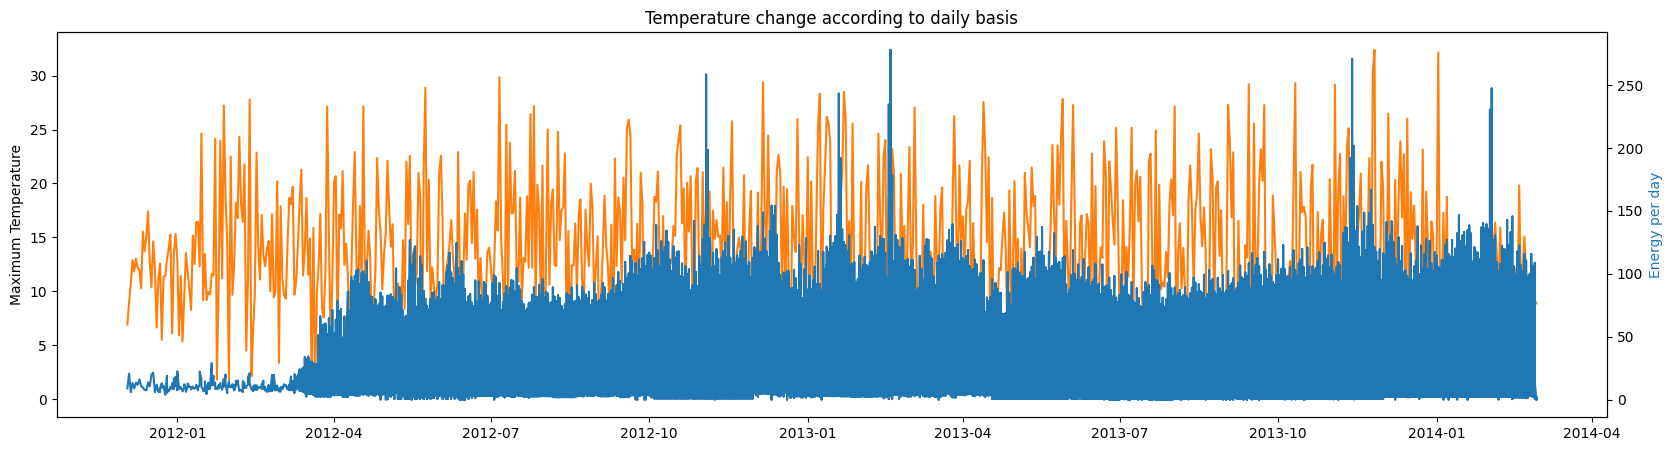

In [25]:
fig, ax1 = plt.subplots(figsize = (20,5))
ax1.plot(merge_dataset.day, merge_dataset.temperatureMax, color = 'tab:orange')

ax1.set_ylabel('Maximum Temperature')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('Temperature change according to daily basis')

plt.show()

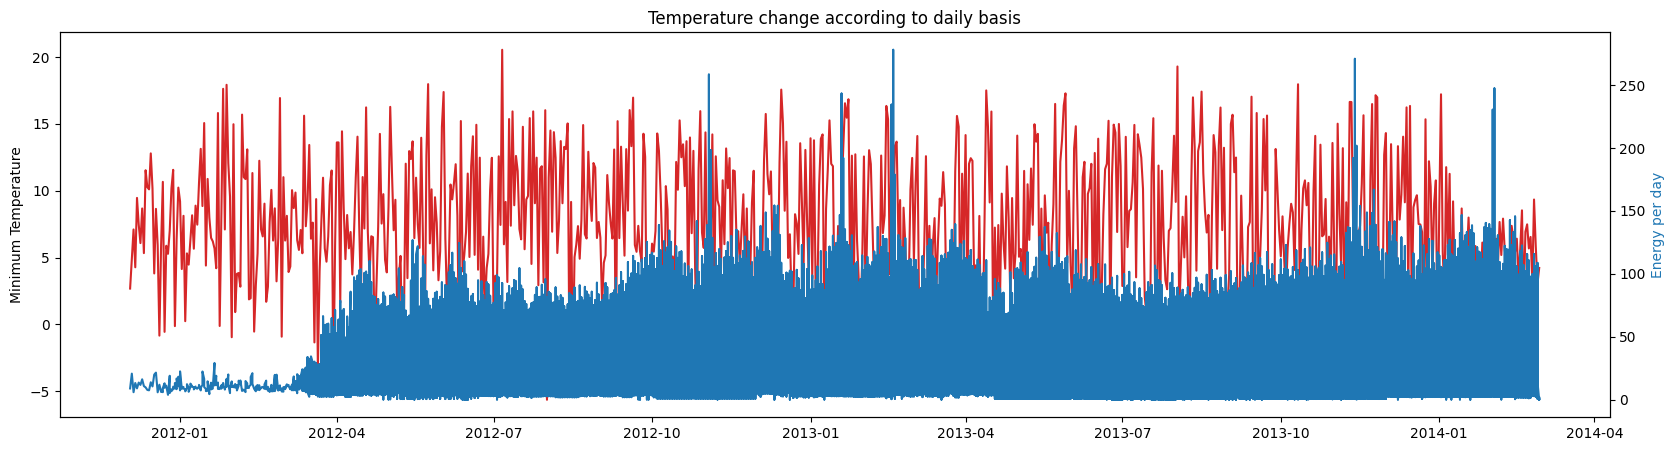

In [26]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.temperatureMin, color = 'tab:red')
ax1.set_ylabel('Minimum Temperature')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('Temperature change according to daily basis')

plt.show()

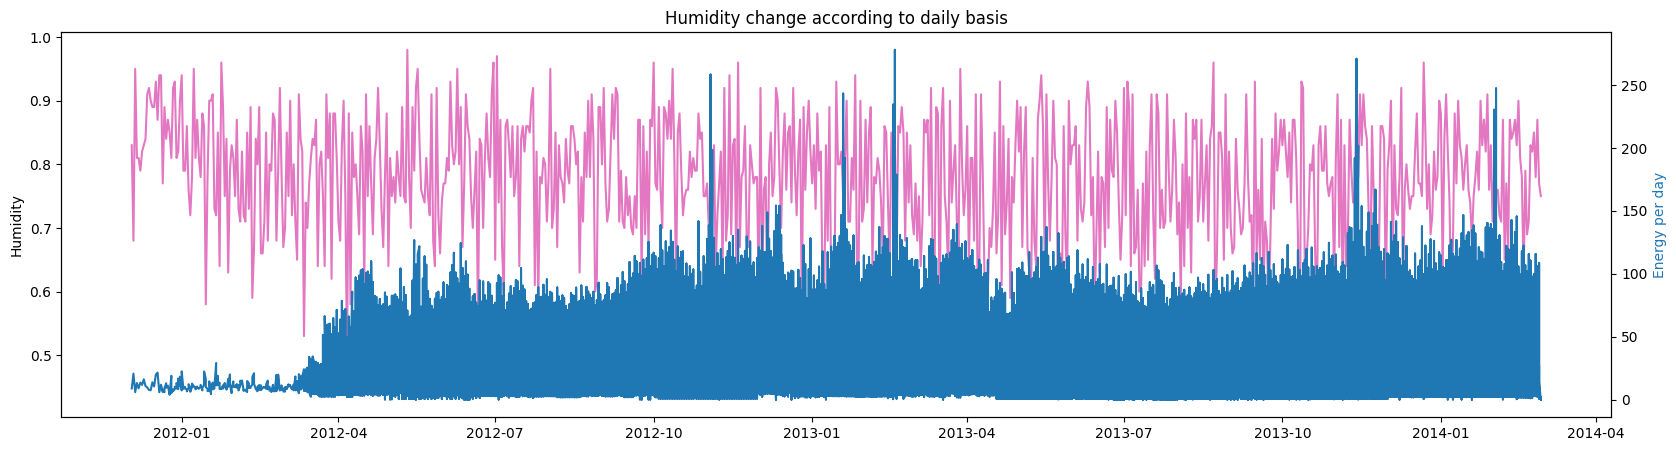

In [27]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.humidity, color = 'tab:pink')
ax1.set_ylabel('Humidity')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('Humidity change according to daily basis')

plt.show()

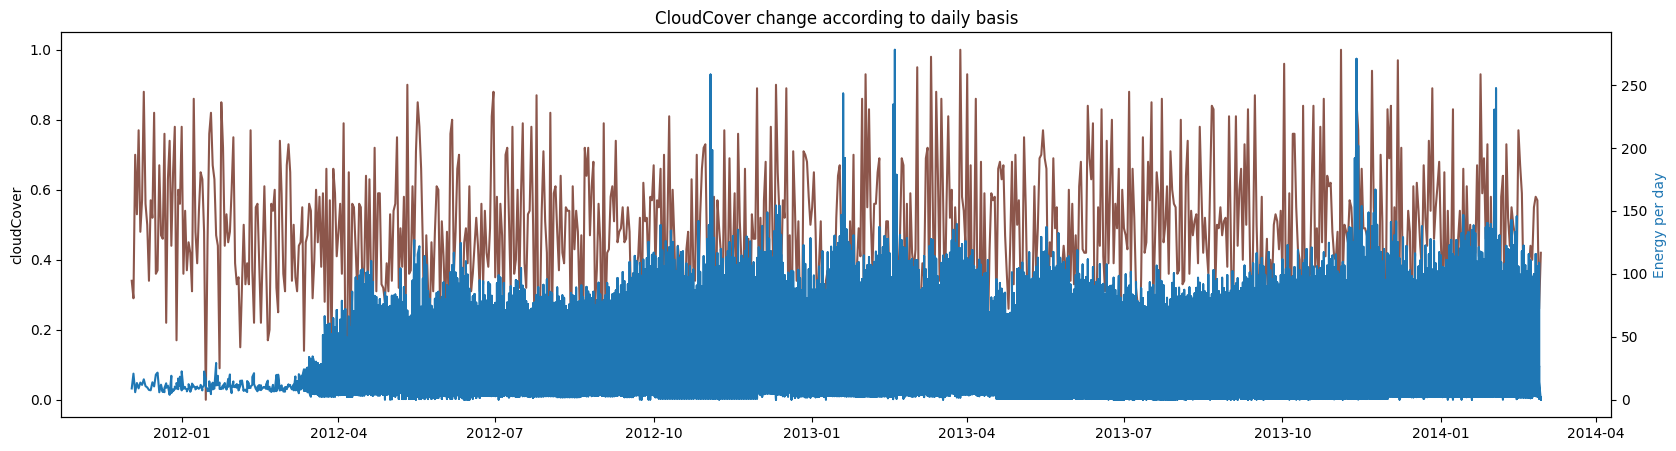

In [28]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.cloudCover, color = 'tab:Brown')
ax1.set_ylabel('cloudCover')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('CloudCover change according to daily basis')

plt.show()

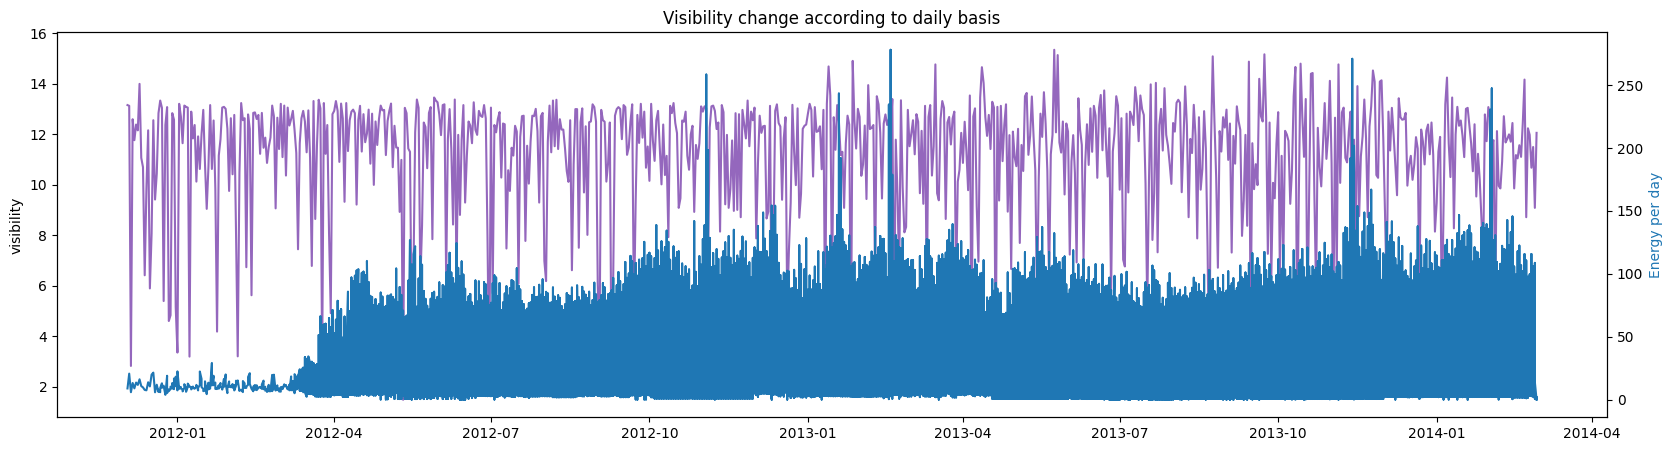

In [29]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.visibility, color = 'tab:Purple')
ax1.set_ylabel('visibility')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('Visibility change according to daily basis')

plt.show()

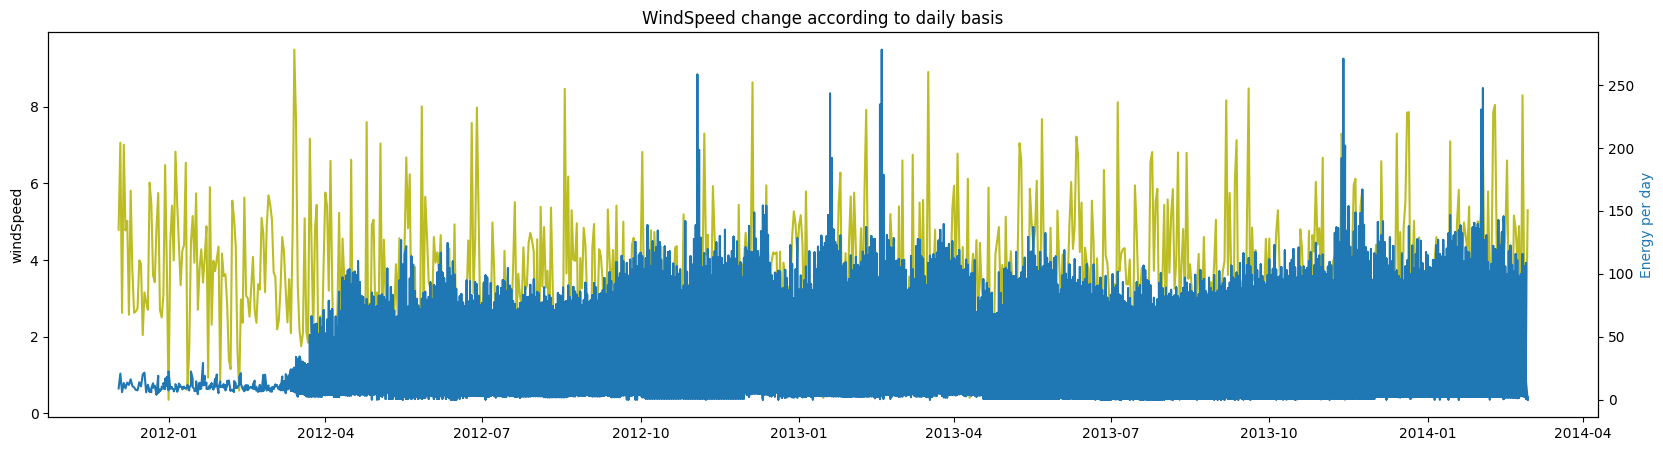

In [30]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.windSpeed, color = 'tab:Olive')
ax1.set_ylabel('windSpeed')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('WindSpeed change according to daily basis')

plt.show()

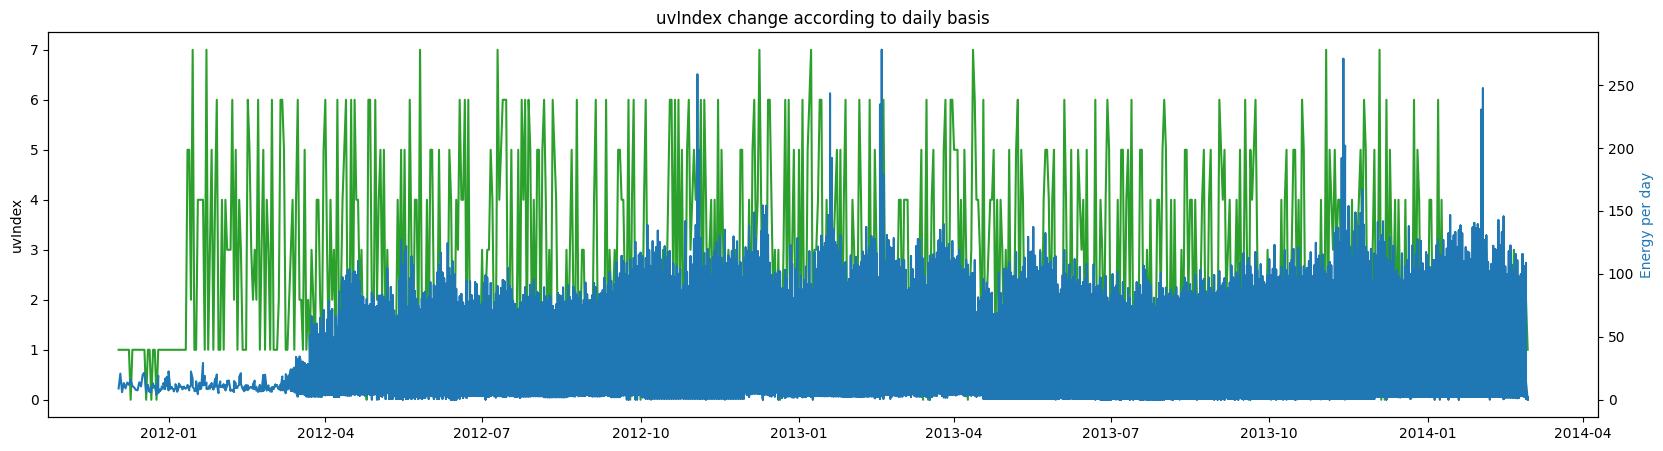

In [31]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.uvIndex, color = 'tab:Green')
ax1.set_ylabel('uvIndex')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('uvIndex change according to daily basis')

plt.show()

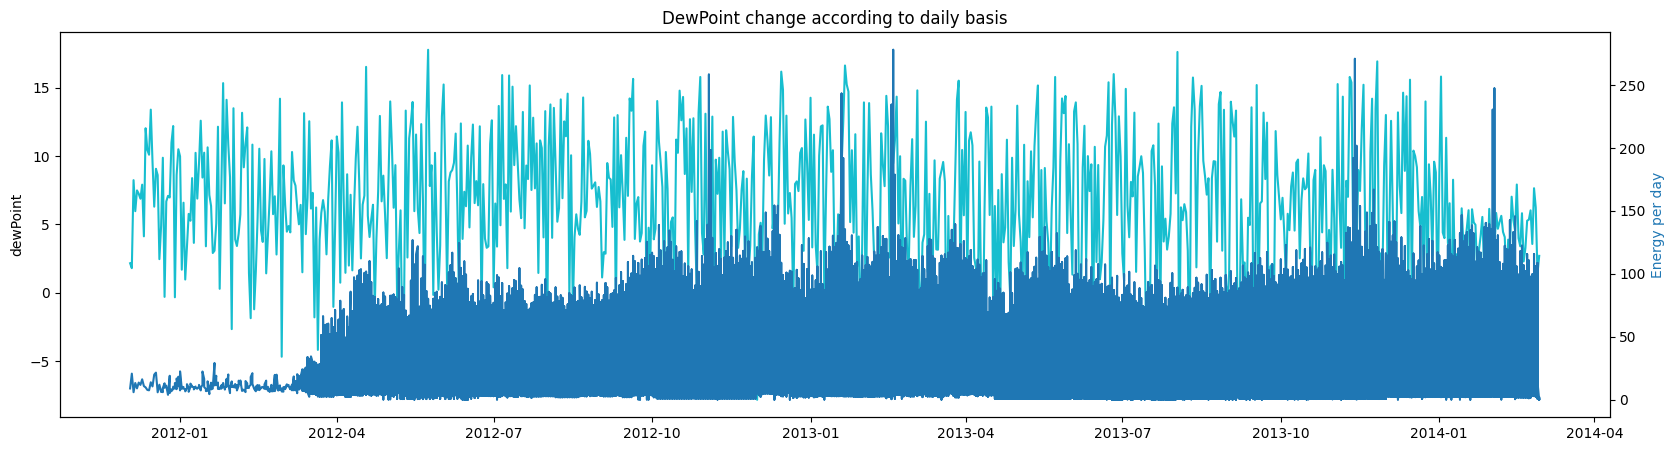

In [32]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.dewPoint, color = 'tab:Cyan')
ax1.set_ylabel('dewPoint')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('DewPoint change according to daily basis')

plt.show()

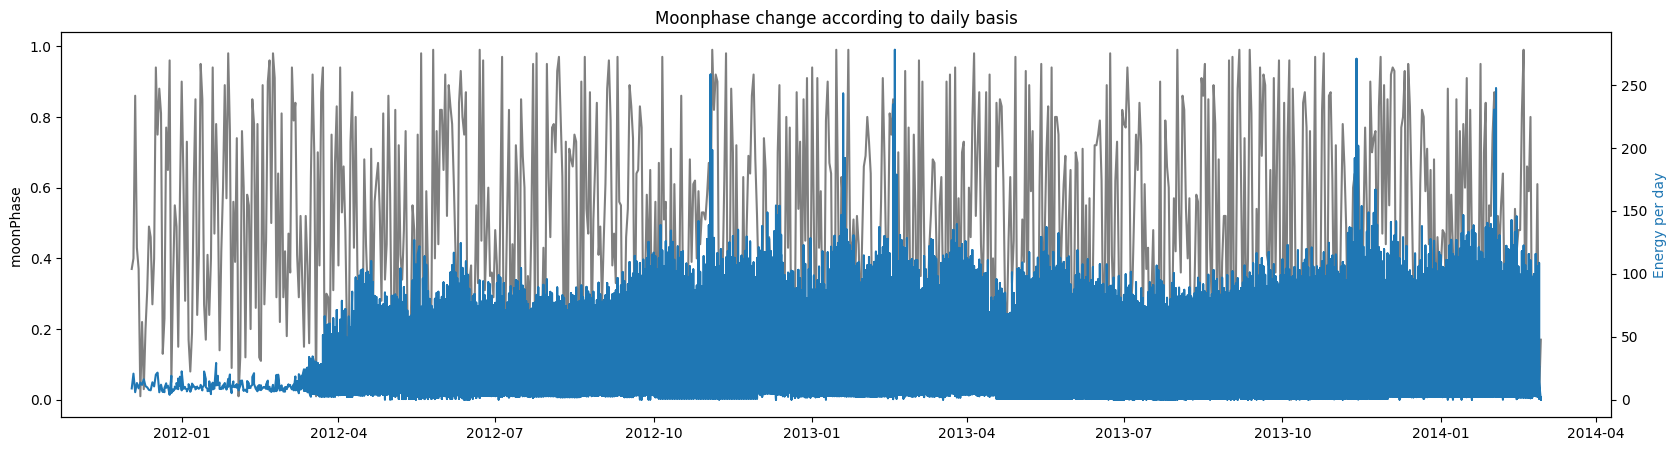

In [33]:
fig, ax1 = plt.subplots(figsize = (20,5))

ax1.plot(merge_dataset.day, merge_dataset.moonPhase, color = 'tab:Grey')
ax1.set_ylabel('moonPhase ')

ax2 = ax1.twinx()
ax2.plot(merge_dataset.day,merge_dataset.energy_sum,color = 'tab:blue')
ax2.set_ylabel('Energy per day',color = 'tab:blue')

plt.title('Moonphase change according to daily basis')

plt.show()